In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
# Apresenta a Dinamica do MDP de forma gráfica
import graphviz
from abc import ABC, abstractmethod

In [2]:
# ============================================================
# CONVENÇÕES DO NOTEBOOK (Padrão A)
#
#   Estado s:
#       s = row * ncol + col, com row = 0 sendo a LINHA DO TOPO.
#       s = 0           -> canto SUPERIOR esquerdo
#       s = nlin*ncol-1 -> canto INFERIOR direito
#
#   Ações (Padrão A):
#       0 = Cima     (dy = +1)
#       1 = Direita  (dx = +1)
#       2 = Baixo    (dy = -1)
#       3 = Esquerda (dx = -1)
#
#   FrozenLake do Gymnasium:
#       - usa s = row * ncol + col com row=0 no TOPO (compatível)
#       - usa ações 0=Left, 1=Down, 2=Right, 3=Up  (INCOMPATÍVEL)
#       - logo, é necessário converter as ações via GYM_TO_MY_ACTION
# ============================================================

In [3]:
try:
    import cupy as cp
    GPU_DISPONIVEL = cp.cuda.runtime.getDeviceCount() > 0
except ImportError:
    GPU_DISPONIVEL = False
    cp = None

In [4]:
# Cria o ambiente 4x4 estocástico
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="rgb_array")

# Acesso ao dicionário de dinâmica do MDP
P = env.unwrapped.P

In [5]:
print(P)

{0: {0: [(0.33333333333333337, 0, 0, False), (0.3333333333333333, 0, 0, False), (0.33333333333333337, 4, 0, False)], 1: [(0.33333333333333337, 0, 0, False), (0.3333333333333333, 4, 0, False), (0.33333333333333337, 1, 0, False)], 2: [(0.33333333333333337, 4, 0, False), (0.3333333333333333, 1, 0, False), (0.33333333333333337, 0, 0, False)], 3: [(0.33333333333333337, 1, 0, False), (0.3333333333333333, 0, 0, False), (0.33333333333333337, 0, 0, False)]}, 1: {0: [(0.33333333333333337, 1, 0, False), (0.3333333333333333, 0, 0, False), (0.33333333333333337, 5, 0, True)], 1: [(0.33333333333333337, 0, 0, False), (0.3333333333333333, 5, 0, True), (0.33333333333333337, 2, 0, False)], 2: [(0.33333333333333337, 5, 0, True), (0.3333333333333333, 2, 0, False), (0.33333333333333337, 1, 0, False)], 3: [(0.33333333333333337, 2, 0, False), (0.3333333333333333, 1, 0, False), (0.33333333333333337, 0, 0, False)]}, 2: {0: [(0.33333333333333337, 2, 0, False), (0.3333333333333333, 1, 0, False), (0.33333333333333

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


array([[[180, 200, 230],
        [180, 200, 230],
        [180, 200, 230],
        ...,
        [180, 200, 230],
        [180, 200, 230],
        [180, 200, 230]],

       [[180, 200, 230],
        [174, 205, 230],
        [174, 205, 230],
        ...,
        [174, 205, 230],
        [174, 205, 230],
        [180, 200, 230]],

       [[180, 200, 230],
        [174, 205, 230],
        [174, 205, 230],
        ...,
        [174, 205, 230],
        [174, 205, 230],
        [180, 200, 230]],

       ...,

       [[180, 200, 230],
        [174, 205, 230],
        [174, 205, 230],
        ...,
        [198, 224, 242],
        [198, 224, 242],
        [180, 200, 230]],

       [[180, 200, 230],
        [174, 205, 230],
        [174, 205, 230],
        ...,
        [198, 224, 242],
        [198, 224, 242],
        [180, 200, 230]],

       [[180, 200, 230],
        [180, 200, 230],
        [180, 200, 230],
        ...,
        [180, 200, 230],
        [180, 200, 230],
        [180, 200, 230]]], dtype=uint8)
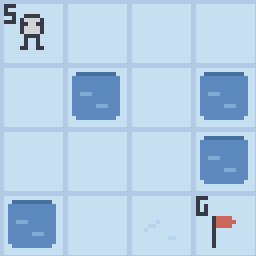

In [6]:
env.reset()
env.render()

In [7]:
# Podemos inspecionar o espaço de ações do ambiente
print("Tipo do espaço de ações:", env.action_space)
print("Número de ações disponíveis:", env.action_space.n)
print("Espaço de estados disponíveis:", env.observation_space.n)

# Embora o nome textual amigável (como 'Esquerda') não venha embutido por padrão de forma direta
# no objeto genérico do Discrete space, podemos associar de forma dinâmica ao tamanho do espaço:
nomes_padrao = ["Left", "Down", "Right", "Up"]
actions_dinamico = {i: nomes_padrao[i] for i in range(env.action_space.n)}
print("\nDicionário gerado dinamicamente baseando-se no número de ações do ambiente:")
print(actions_dinamico)

Tipo do espaço de ações: Discrete(4)
Número de ações disponíveis: 4
Espaço de estados disponíveis: 16

Dicionário gerado dinamicamente baseando-se no número de ações do ambiente:
{0: 'Left', 1: 'Down', 2: 'Right', 3: 'Up'}


In [8]:
import graphviz

def visualize_mdp_adaptada(P, env):
    dot = graphviz.Digraph(comment='MDP FrozenLake 4x4')
    dot.attr(rankdir='LR') # Layout da esquerda para a direita

    # Mapeamento de ações do FrozenLake para exibição gráfica
    dict_acoes = {
        0: "◄ Left",
        1: "▼ Down",
        2: "► Right",
        3: "▲ Up"
    }

    # No FrozenLake 4x4 padrão:
    # 0 é o início. 5, 7, 11, 12 são buracos (Holes / Terminais com recompensa 0).
    # 15 é a meta (Goal / Terminal com recompensa 1).
    estado_inicial = 0
    buracos = {5, 7, 11, 12}
    objetivo = 15

    # Adiciona estados (nós)
    for s in P.keys():
        state_label = f"Estado {s}"

        if s == estado_inicial:
            dot.node(str(s), label=f'{state_label} (Inicio)', style='filled', fillcolor='lightgreen')
        elif s in buracos:
            dot.node(str(s), label=f'{state_label} (Buraco)', style='filled', fillcolor='lightcoral')
        elif s == objetivo:
            dot.node(str(s), label=f'{state_label} (Objetivo!)', style='filled', fillcolor='gold')
        else:
            dot.node(str(s), label=state_label)

    # Adiciona transições (arestas)
    for s in P.keys():
        # Se for um estado terminal clássico (buraco ou objetivo), suas transições são apenas loops neles mesmos.
        # Para não poluir demais o gráfico de um ambiente estocástico, adicionamos as arestas de transição:
        for a in P[s].keys():
            action_label = dict_acoes.get(a, str(a))
            for prob, s_linha, recompensa, done in P[s][a]:
                # Só desenha a aresta se a probabilidade for maior que zero
                if prob > 0:
                    edge_label = f'{action_label}\nP={prob:.2f}\nR={recompensa}'
                    if done:
                        edge_label += '\n(Fim)'
                    dot.edge(str(s), str(s_linha), label=edge_label)
    return dot



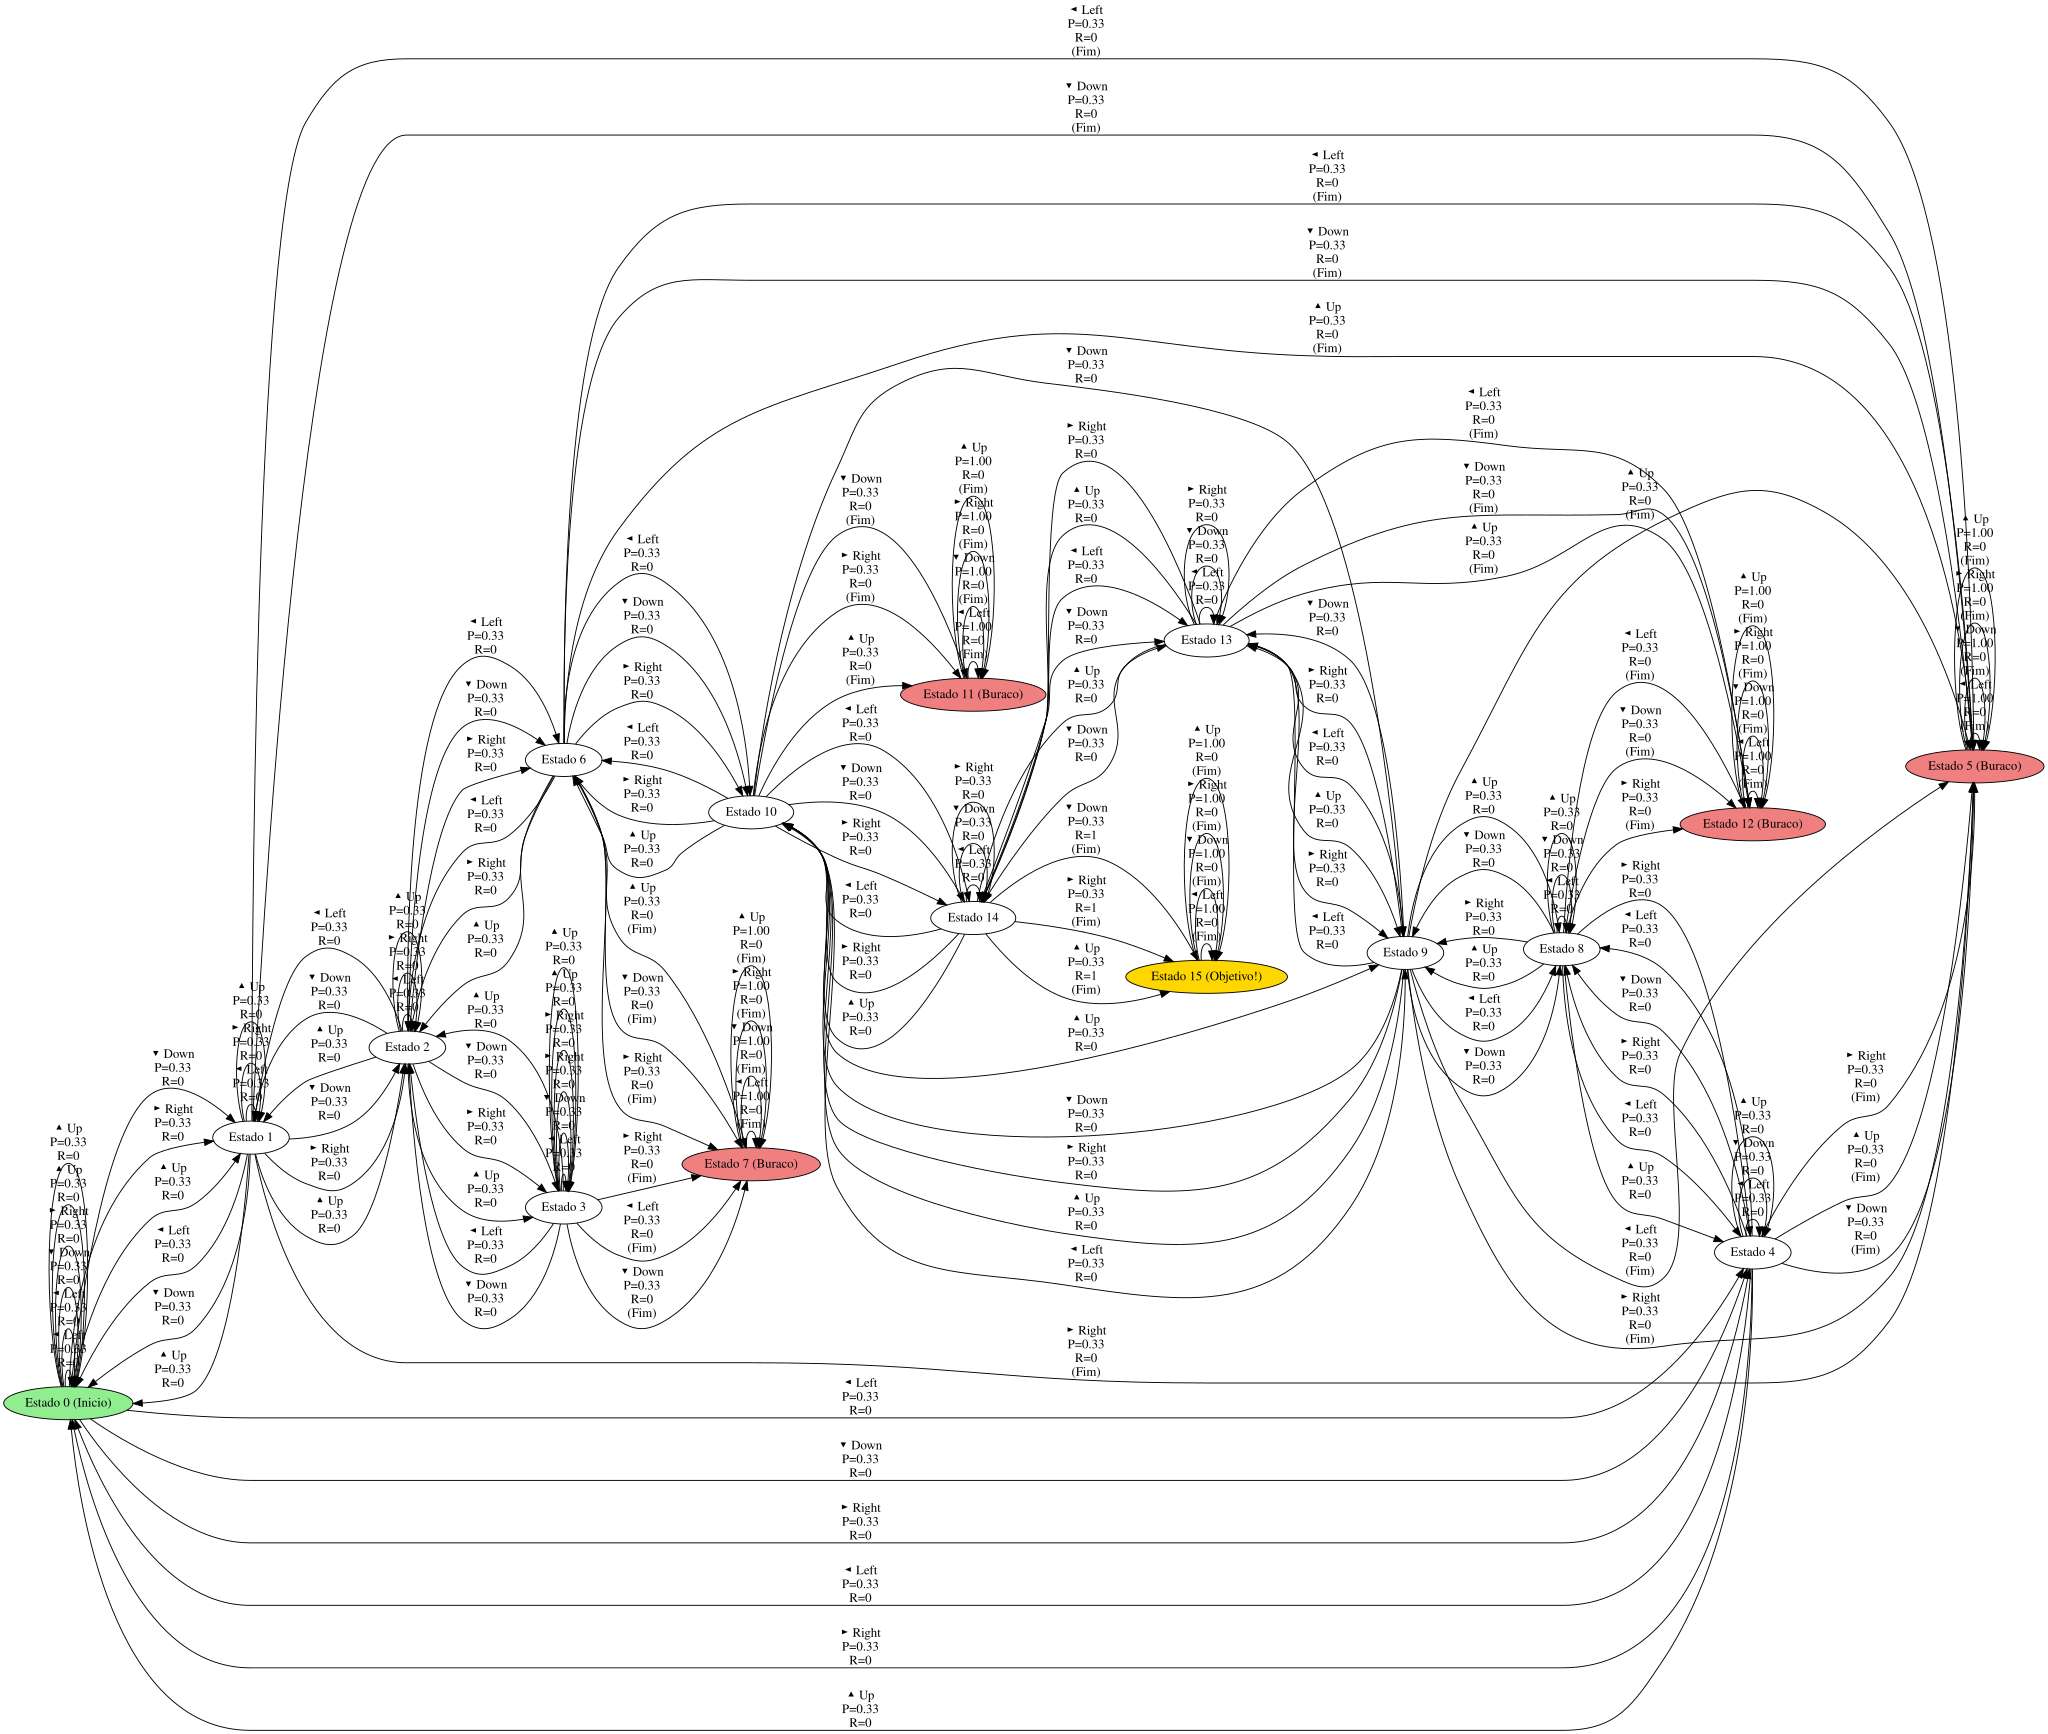

In [9]:
# Gera e exibe o MDP graficamente
grafo_mdp = visualize_mdp_adaptada(P, env)
grafo_mdp

In [10]:
# ============================================================
# Conversão de ações: Padrão A <-> Gymnasium FrozenLake
#
#   Padrão A:   0=Cima,    1=Direita, 2=Baixo,   3=Esquerda
#   Gym:        0=Left,    1=Down,    2=Right,   3=Up
#
#   Mapeamento:
#       Padrão A 0 (Cima)     <-> Gym 3 (Up)
#       Padrão A 1 (Direita)  <-> Gym 2 (Right)
#       Padrão A 2 (Baixo)    <-> Gym 1 (Down)
#       Padrão A 3 (Esquerda) <-> Gym 0 (Left)
# ============================================================
MY_TO_GYM_ACTION = {
    0: 3,  # Padrão A: Cima     -> Gym: Up
    1: 2,  # Padrão A: Direita  -> Gym: Right
    2: 1,  # Padrão A: Baixo    -> Gym: Down
    3: 0,  # Padrão A: Esquerda -> Gym: Left
}
GYM_TO_MY_ACTION = {v: k for k, v in MY_TO_GYM_ACTION.items()}

def build_my_P(gym_P):
    """Converte P do Gym (ações Gym) para P no Padrão A (ações Padrão A)."""
    my_P = {}
    for s in gym_P:
        temp = {}
        for gym_a, transitions in gym_P[s].items():
            my_a = GYM_TO_MY_ACTION[gym_a]
            temp[my_a] = transitions
        my_P[s] = {a: temp[a] for a in sorted(temp.keys())}
    return my_P

In [11]:
P_dyn = build_my_P(P)
P_dyn

{0: {0: [(0.33333333333333337, 1, 0, False),
   (0.3333333333333333, 0, 0, False),
   (0.33333333333333337, 0, 0, False)],
  1: [(0.33333333333333337, 4, 0, False),
   (0.3333333333333333, 1, 0, False),
   (0.33333333333333337, 0, 0, False)],
  2: [(0.33333333333333337, 0, 0, False),
   (0.3333333333333333, 4, 0, False),
   (0.33333333333333337, 1, 0, False)],
  3: [(0.33333333333333337, 0, 0, False),
   (0.3333333333333333, 0, 0, False),
   (0.33333333333333337, 4, 0, False)]},
 1: {0: [(0.33333333333333337, 2, 0, False),
   (0.3333333333333333, 1, 0, False),
   (0.33333333333333337, 0, 0, False)],
  1: [(0.33333333333333337, 5, 0, True),
   (0.3333333333333333, 2, 0, False),
   (0.33333333333333337, 1, 0, False)],
  2: [(0.33333333333333337, 0, 0, False),
   (0.3333333333333333, 5, 0, True),
   (0.33333333333333337, 2, 0, False)],
  3: [(0.33333333333333337, 1, 0, False),
   (0.3333333333333333, 0, 0, False),
   (0.33333333333333337, 5, 0, True)]},
 2: {0: [(0.33333333333333337, 3, 0

In [12]:
class Tabuleiro(gym.Env):
    """
    Gym.Env do tabuleiro MDP.

    ─── CONVENÇÃO (Padrão A) ────────────────────────────────────
        _state_to_coords(s) -> (x, y) com y crescendo PARA CIMA.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.
        s = 0 -> (0, nlin-1) -> canto SUPERIOR esquerdo.
    """

    def __init__(self, P_Din_MDP=None, nlin=4, ncol=4,
                 estado_inicial=0, max_steps=500):
        if not (nlin > 0 and ncol > 0):
            raise AssertionError('nlin e ncol devem ser positivas')
        if estado_inicial < 0 or estado_inicial >= nlin * ncol:
            raise AssertionError(
                f'estado_inicial deve estar entre 0 e {nlin*ncol-1}')
        if P_Din_MDP is None:
            raise AssertionError('A Dinâmica do MDP deve ser definida')

        nestados = nlin * ncol
        if nestados != max(P_Din_MDP.keys()) + 1 or \
           nestados != len(P_Din_MDP):
            raise AssertionError(
                f'A Dinâmica do MDP deve ter {nlin*ncol} estados')

        super().__init__()
        self.nlin, self.ncol = nlin, ncol
        self.num_acoes = 4
        self.passo = 0
        self.max_steps = max_steps
        self.P_Din_MDP = P_Din_MDP

        self.action_space = spaces.Discrete(self.num_acoes)
        self.dict_acoes = {0: 'cima', 1: 'dir', 2: 'baixo', 3: 'esq'}
        self.dict_acoes_inv = {'cima': 0, 'dir': 1, 'baixo': 2, 'esq': 3}

        self.num_estados = nestados
        self.estado_inicial = estado_inicial
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.state_space = spaces.Discrete(self.num_estados)

        self.dict_estados = {i: f's{i}' for i in range(self.num_estados)}
        self.dict_estados_inv = {f's{i}': i for i in range(self.num_estados)}

        self.visited_states = {self.estado_inicial}

        self.render()

    # ---------- Conversões (Padrão A) ----------
    def _state_to_coords(self, state):
        """s -> (x, y) com y crescendo PARA CIMA."""
        row = state // self.ncol
        col = state % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    def _coords_to_state(self, x, y):
        """(x, y) com y crescendo PARA CIMA -> s."""
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    # ---------- Gym API ----------
    def step(self, acao):
        transitions = self.P_Din_MDP[self.state][acao]
        probs = [p for p, _, _, _ in transitions]
        outcomes = [(s2, r, d) for _, s2, r, d in transitions]

        idx = np.random.choice(len(outcomes), p=probs)
        next_state, reward, terminated = outcomes[idx]

        self.state = next_state
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states.add(self.state)
        self.passo += 1

        truncated = self.passo >= self.max_steps
        self.render()
        return self.state, reward, terminated, truncated, {}

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states = {self.estado_inicial}
        self.render()
        return self.state, {}

    def _is_terminal(self, s):
        if s not in self.P_Din_MDP:
            return True
        for a in self.P_Din_MDP[s]:
            for _, _, _, done in self.P_Din_MDP[s][a]:
                if not done:
                    return False
        return True

    # ---------- Render (Padrão A — SEM invert_yaxis) ----------
    def render(self):
        fig, ax = plt.subplots(figsize=(self.ncol, self.nlin))
        ax.set_aspect('equal')

        for x in range(self.ncol + 1):
            ax.axvline(x, color='black', lw=1)
        for y in range(self.nlin + 1):
            ax.axhline(y, color='black', lw=1)

        ax.set_xlim(0, self.ncol)
        ax.set_ylim(0, self.nlin)
        ax.set_xticks([]); ax.set_yticks([])

        for s in range(self.num_estados):
            x, y = self._state_to_coords(s)
            xc, yc = x + 0.5, y + 0.5

            ax.text(xc, yc, self.dict_estados[s],
                    ha='center', va='center', fontsize=12)

            if s == self.estado_inicial:
                ax.text(x + 0.1, y + 0.9, 'I', ha='left', va='top',
                        fontsize=10, color='green', fontweight='bold')
            if self._is_terminal(s):
                ax.text(x + 0.1, y + 0.9, 'T', ha='left', va='top',
                        fontsize=10, color='red', fontweight='bold')
            if s in self.visited_states and s != self.state:
                ax.text(xc, yc + 0.2, 'x', ha='center', va='center',
                        fontsize=16, color='gray')
            if s == self.state:
                ax.text(xc, yc - 0.2, 'o', ha='center', va='center',
                        fontsize=16, color='blue', fontweight='bold')

        plt.title('Tabuleiro MDP (Padrão A)')
        plt.show()

    def close(self):
        plt.close()

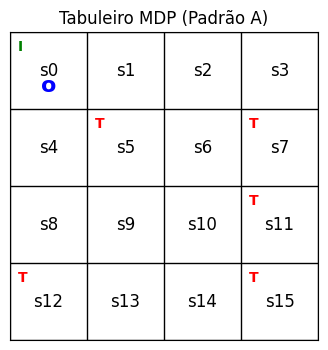

In [13]:
env_tab = Tabuleiro(P_dyn, nlin = 4, ncol = 4)

In [14]:
# 1. Acessa a matriz de caracteres crua (em bytes)
desc_bytes = env.unwrapped.desc

print("--- Imprimindo linha por linha ---")
# Decodifica elemento por elemento em cada linha e junta em uma única string por linha
board_strings = ["".join([cell.decode("utf-8") for cell in line]) for line in desc_bytes]

# Imprime as linhas decodificadas
for line in board_strings:
    print(line)

--- Imprimindo linha por linha ---
SFFF
FHFH
FFFH
HFFG


In [15]:
# Interface da Classe Base usando o Padrão Strategy
class AvaliadorMDP(ABC):
    # recebe o ambiente env, o pacote de vetores (numpy ou cupy em xp) e a constante gama
    def __init__(self, env, xp, gamma = 0.99):
        self.env, self.xp, self.gamma = env, xp, gamma

    @abstractmethod
    def q_valor(self, s, a, V): ...  # escalar (útil em PI iterativa)

    @abstractmethod
    def q_valores(self, V): ...      # retorna array (S, A)

In [16]:
class AvaliadorIterativo(AvaliadorMDP):
    # calcula q(s, a) varrendo uma linha do dicionário com as chaves s e a
    def q_valor(self, s, a, V):
        total = 0.0
        for p, s2, r, _ in self.env.P_Din_MDP[s][a]:
            total += p * (r + self.gamma * V[s2])
        return total # escalar (útil em PI iterativa)

    # calcula q(s, a) para todos os pares (s, a), todas as linhas do dicionário
    def q_valores(self, V):
        return self.xp.array([
            [self.q_valor(s, a, V) for a in range(self.env.num_acoes)]
            for s in range(self.env.num_estados)
        ]) # retorna array (S, A)

In [17]:
# Versão para utilização com Numpy e Cupy/GPU
# Funciona com a GPU quando esta for disponibilizada na versão livre do Google Colab
class AvaliadorVetorizado(AvaliadorMDP):
    def __init__(self, env, xp, gamma):
        super().__init__(env, xp, gamma)
        self.T, self.R, self.mask_term = self._construir(env, xp)

    @staticmethod
    def _construir(env, xp):
        # T = P(s'/s, a) - Modelo de Transição de Estados
        # R = R(s, a) - Valor esperado da recompensa ao tomar a ação a, a partir do estado s
        # mask - máscara para estado terminal, 1 se s é terminal, 0 o contrário
        S, A = env.num_estados, env.num_acoes
        T = xp.zeros((S, A, S), dtype=xp.float32)
        R = xp.zeros((S, A), dtype=xp.float32)
        mask = xp.zeros(S, dtype=xp.bool_)
        for s in range(S):
            # Revertendo para sintaxe NumPy para atribuição direta
            mask[s] = env._is_terminal(s)
            for a in range(A):
                for p, s2, r, _ in env.P_Din_MDP.get(s, {}).get(a, []):
                    # Revertendo para sintaxe NumPy para atribuição direta
                    T[s, a, s2] += p
                    # Revertendo para sintaxe NumPy para atribuição direta
                    R[s, a]    += p * r
        return T, R, mask

    # calcula q(s, a) varrendo uma linha do dicionário com as chaves s e a
    def q_valor(self, s, a, V):
        # escalar (útil em PI iterativa)
        return float(self.R[s, a] + self.gamma * self.T[s, a] @ V) # escalar (útil em PI iterativa)

    # calcula q(s, a) para todos os pares (s, a), todas as linhas do dicionário
    def q_valores(self, V):
        # retorna array (S, A)
        # einsum effectively calculates sum_n (T[s, a, n] * V[n]) for each pair (s, a)
        # n - índice da próxima dimensão do estado - next state
        return self.R + self.gamma * self.xp.einsum('san,n->sa', self.T, V)

In [18]:
# ---------- 2. Template Method: esqueleto VI/PI ----------
class AlgoritmoPlanejamento(ABC):
    def __init__(self, env, avaliador: AvaliadorMDP, gamma=0.99, epsilon=1e-6):
        self.env, self.avaliador, self.gamma, self.epsilon = env, avaliador, gamma, epsilon
        self.xp = avaliador.xp
        S = env.num_estados
        self.V = self.xp.zeros(S, dtype=self.xp.float32)
        # _politica_det é a política determinística interna para cálculos e avaliação
        self._politica_det = self.xp.zeros(S, dtype=self.xp.int32)
        # politica é a política estocástica final (lista de listas)
        self.politica = None

    def treinar(self, max_iteracoes=1000, reset = True):
        if reset:
            self.reset()

        for i in range(max_iteracoes):
            if self._passo(i) < self.epsilon:
                print(f"[{type(self).__name__} | {type(self.avaliador).__name__}] "
                      f"convergiu em {i+1} iterações.")
                break
        self._extrair_politica()
        return self.V, self.politica

    def reset(self):
        """Zera V e politica para o estado inicial."""
        self.V = self.xp.zeros(self.env.num_estados, dtype=self.xp.float32)
        self._politica_det = self.xp.zeros(self.env.num_estados, dtype=self.xp.int32)
        self.politica = None

    @abstractmethod
    def _passo(self, i: int) -> float: ...

    @abstractmethod
    def _extrair_politica(self): ...

In [19]:
class IteracaoValor(AlgoritmoPlanejamento):
    def _passo(self, i):
        V_old = self.xp.copy(self.V)
        Q = self.avaliador.q_valores(V_old)
        self.V = self.xp.max(Q, axis=1)

        # Fix: Properly handle evaluators that don't have 'mask_term'
        # Condição de contorno: V de estado terminal é nula
        if hasattr(self.avaliador, 'mask_term'):
            # Se o avaliador fornece uma máscara para estados terminais, use-a
            self.V[self.avaliador.mask_term] = 0.0
        else:
            # Fallback para avaliadores que não fornecem mask_term (e.g., AvaliadorIterativo)
            # Podemos obter a informação do estado terminal do próprio ambiente
            terminal_mask = self.xp.array([self.env._is_terminal(s) for s in range(self.env.num_estados)], dtype=self.xp.bool_)
            self.V[terminal_mask] = 0.0

        return float(self.xp.max(self.xp.abs(self.V - V_old)))

    def _extrair_politica(self):
        Q = self.avaliador.q_valores(self.V)
        # A política determinística interna é a primeira ação ótima
        self._politica_det = self.xp.argmax(Q, axis=1)

        # Gerar a política estocástica (lista de listas) para o atributo 'politica' público
        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy



In [20]:
class _BaseIteracaoPolitica(AlgoritmoPlanejamento, ABC):
    """
    Esqueleto comum de PI e MPI corrigido.
    Para evitar convergência prematura quando a política inicial coincide com a do primeiro passo,
    rastreamos se a função de valor V também mudou significativamente, ou se é o primeiro passo.
    """

    def _passo(self, i):
        V_old = self.xp.copy(self.V)

        # (a) Avaliação — delegada ao hook (_avaliar de PI ou MPI)
        self._avaliar()

        # (b) Melhoria — fixa
        Q = self.avaliador.q_valores(self.V)
        nova_politica_det = self.xp.argmax(Q, axis=1)

        # Uma política é considerada estável se ela não mudou E a função de valor V também convergiu
        politica_estavel = bool(self.xp.all(nova_politica_det == self._politica_det))
        valor_estabilizado = float(self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon

        # Atualiza a política determinística interna
        self._politica_det = nova_politica_det

        # Só paramos se a política for estável E o valor tiver convergido (evita parada prematura em MPI)
        if i > 0 and politica_estavel and valor_estabilizado:
            return 0.0

        return 1.0

    def _extrair_politica(self):
        # Calcula os Q-valores usando o V final
        Q = self.avaliador.q_valores(self.V)

        # Gerar a política estocástica (lista de listas) para o atributo 'politica' público
        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy

    @abstractmethod
    def _avaliar(self):
        """Executa a avaliação da política corrente sobre self.V."""
        ...

In [21]:
class IteracaoPolitica(_BaseIteracaoPolitica):
    def _avaliar(self):
        while True:
            V_old = self.xp.copy(self.V)
            Q = self.avaliador.q_valores(V_old)
            idx = self.xp.arange(self.env.num_estados)
            # Usa a política determinística interna para avaliação
            self.V = Q[idx, self._politica_det]
            if float(self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon:
                break

In [22]:
class IteracaoPoliticaModificada(_BaseIteracaoPolitica):
    def __init__(self, env, avaliador, gamma=0.99, epsilon=1e-6, k=1):
        super().__init__(env, avaliador, gamma, epsilon)
        if k < 1:
            raise ValueError("k deve ser >= 1")
        self.k = k

    def _avaliar(self):
        idx = self.xp.arange(self.env.num_estados)
        for _ in range(self.k):
            Q = self.avaliador.q_valores(self.V)
            # Usa a política determinística interna para avaliação
            self.V = Q[idx, self._politica_det]

In [23]:
def _sanity_check_P_dyn_A(P_dyn, nlin=4, ncol=4):
    """
    Sanity check do P_dyn em Padrão A para FrozenLake ESCORREGADIO.
    Reflete fielmente a regra do Gymnasium: ação escolhida + 2 perpendiculares,
    nunca a oposta.
    """
    def agregar(s, a):
        acc = {}
        for prob, s2, r, done in P_dyn[s][a]:
            acc[s2] = acc.get(s2, 0.0) + prob
        return acc

    # 1) Todas as ações de todos os estados têm probabilidades somando 1
    for s in range(nlin * ncol):
        for a in range(4):
            total = sum(p for p, _, _, _ in P_dyn[s][a])
            assert abs(total - 1.0) < 1e-6, \
                f"Soma de probs (s={s},a={a}) = {total}, deveria ser 1"

    # 2) Estados terminais absorventes (buracos 5,7,11,12; objetivo 15)
    for s in [5, 7, 11, 12, 15]:
        for a in range(4):
            for prob, s2, r, done in P_dyn[s][a]:
                assert done, f"s={s} deveria ser terminal"
                assert s2 == s, f"s={s} terminal deveria ficar em si mesmo"

    # 3) Recompensa +1 existe entrando em s=15
    assert any(
        r == 1.0 and s2 == 15
        for s in range(16) for a in range(4)
        for _, s2, r, _ in P_dyn[s][a]
    ), "Nenhuma transição com reward +1 para s=15"

    # 4) Testes específicos a partir de s=0
    #    (todos com a regra: principal + 2 perpendiculares)
    dest = agregar(0, 0)  # Cima
    assert abs(dest.get(0, 0) - 2/3) < 1e-6, \
        f"Cima de s=0: P(ficar em 0) = {dest.get(0,0)}, esperado 2/3"
    assert abs(dest.get(1, 0) - 1/3) < 1e-6, \
        f"Cima de s=0: P(ir para 1) = {dest.get(1,0)}, esperado 1/3"

    dest = agregar(0, 2)  # Baixo
    assert set(dest.keys()) == {0, 1, 4}, \
        f"Baixo de s=0 deveria levar a {{0,1,4}}, foi {set(dest.keys())}"
    for k in dest:
        assert abs(dest[k] - 1/3) < 1e-6, \
            f"Baixo de s=0: P({k}) = {dest[k]}, esperado 1/3"

    dest = agregar(0, 3)  # Esquerda
    assert abs(dest.get(0, 0) - 2/3) < 1e-6, \
        f"Esquerda de s=0: P(ficar em 0) = {dest.get(0,0)}, esperado 2/3"
    assert abs(dest.get(4, 0) - 1/3) < 1e-6, \
        f"Esquerda de s=0: P(ir para 4) = {dest.get(4,0)}, esperado 1/3"

    dest = agregar(0, 1)  # Direita
    assert set(dest.keys()) == {0, 1, 4}, \
        f"Direita de s=0 deveria levar a {{0,1,4}}, foi {set(dest.keys())}"

    print("✅ Sanity check P_dyn Padrão A (FrozenLake escorregadio): OK")




In [24]:
_sanity_check_P_dyn_A(P_dyn, nlin=4, ncol=4)

✅ Sanity check P_dyn Padrão A (FrozenLake escorregadio): OK


In [25]:
aval_gamma = 0.99

aval_iter = AvaliadorIterativo(env_tab, xp=np, gamma=aval_gamma)
aval_vet = AvaliadorVetorizado(env_tab, xp=cp if GPU_DISPONIVEL else np, gamma=aval_gamma)

In [26]:
vi_iter = IteracaoValor(env_tab, aval_iter)
vi_vet  = IteracaoValor(env_tab, aval_vet)
pi_iter = IteracaoPolitica(env_tab, aval_iter)
pi_vet  = IteracaoPolitica(env_tab, aval_vet)
mpi_iter = IteracaoPoliticaModificada(env_tab, aval_iter)
mpi_vet  = IteracaoPoliticaModificada(env_tab, aval_vet)

In [27]:
vi_iter.treinar()

[IteracaoValor | AvaliadorIterativo] convergiu em 305 iterações.


(array([0.5420104 , 0.49878234, 0.47067103, 0.45682505, 0.5584366 ,
        0.        , 0.3583369 , 0.        , 0.59178656, 0.6430707 ,
        0.61519957, 0.        , 0.        , 0.741714  , 0.8628341 ,
        0.        ], dtype=float32),
 [[3],
  [0],
  [0],
  [0],
  [3],
  [0, 1, 2, 3],
  [1, 3],
  [0, 1, 2, 3],
  [0],
  [2],
  [3],
  [0, 1, 2, 3],
  [0, 1, 2, 3],
  [1],
  [2],
  [0, 1, 2, 3]])

In [28]:
from matplotlib.patches import Rectangle
class VisualizadorResultado:
    """
    Visualizador em Padrão A:
        s -> (x, y) via tab._state_to_coords(s),
        com y=0 embaixo e y=nlin-1 em cima.
        s=0 -> (0, nlin-1) -> canto superior esquerdo.
    """
    ACOES_DXY = {
        0: ( 0,   0.3), # Cima  -> +y
        1: ( 0.3, 0), # Dir   -> +x
        2: ( 0,  -0.3), # Baixo -> -y
        3: (-0.3, 0), # Esq   -> -x
    }

    def __init__(self, tab, cmap_valores="viridis"):
        self.tab = tab
        self.cmap = plt.get_cmap(cmap_valores)

    def _para_numpy(self, x, dtype=None):
        if x is None:
            return None
        if hasattr(x, "get") and not isinstance(x, np.ndarray):
            x = x.get()                                   # CuPy
        elif hasattr(x, "cpu") and not isinstance(x, np.ndarray):
            x = x.cpu().numpy()                           # PyTorch
        return np.asarray(x, dtype=dtype)

    def _transicao_mais_provavel(self, s, a):
        transicoes = self.tab.P_Din_MDP[s][a]
        return max(transicoes, key=lambda t: t[0])[1]

    def _simular_politica(self, politica, s0=None, max_passos=500):
        tab = self.tab
        if s0 is None:
            s0 = tab.estado_inicial
        s = s0
        caminho = [s]
        for _ in range(max_passos):
            action_to_take = politica[s][0] if isinstance(politica[s], list) else politica[s]
            a = int(action_to_take)
            s_prox = self._transicao_mais_provavel(s, a)
            if tab._is_terminal(s) or s_prox == s:
                break
            caminho.append(s_prox)
            if tab._is_terminal(s_prox):
                break
            s = s_prox
        return caminho

    def desenhar(self, V, politica, ax=None,
                 mostrar_valores=True, mostrar_setas=True,
                 mostrar_rastro=True, mostrar_estados=True, titulo=None):

        tab = self.tab
        V = self._para_numpy(V, dtype=float)

        if ax is None:
            fig, ax = plt.subplots(figsize=(tab.ncol, tab.nlin))

        vmin, vmax = float(V.min()), float(V.max())
        vnorm = np.zeros_like(V) if vmax - vmin < 1e-12 else (V - vmin) / (vmax - vmin)

        caminho = set(self._simular_politica(politica)) if mostrar_rastro else set()

        for s in range(tab.num_estados):
            x, y = tab._state_to_coords(s)
            terminal = tab._is_terminal(s)
            face = "#dddddd" if terminal else self.cmap(vnorm[s])

            ax.add_patch(Rectangle((x, y), 1, 1, facecolor=face,
                                   edgecolor="gray", linewidth=0.8, alpha=0.9))
            if s == tab.estado_inicial:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="orange", linewidth=3))
            if terminal:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="green", linewidth=2))

            if mostrar_estados:
                ax.text(x + 0.08, y + 0.92, tab.dict_estados[s],
                        ha="left", va="top", fontsize=7, color="black", alpha=0.6)
            if mostrar_valores:
                ax.text(x + 0.5, y + 0.5, f"{V[s]:.2f}",
                        ha="center", va="center", fontsize=9,
                        color="white", fontweight="bold")

        if mostrar_setas:
            for s in range(tab.num_estados):
                if tab._is_terminal(s):
                    continue
                x, y = tab._state_to_coords(s)

                actions_to_draw = politica[s] if isinstance(politica[s], list) else [politica[s]]

                for action in actions_to_draw:
                    dx, dy = self.ACOES_DXY[int(action)]
                    cor = "red" if s in caminho else "blue"
                    lw = 2.2 if s in caminho else 1.2
                    ax.annotate("", xy=(x + 0.5 + dx, y + 0.5 + dy), xytext=(x + 0.5, y + 0.5),
                                arrowprops=dict(arrowstyle="->", color=cor, lw=lw, mutation_scale=10))

        ax.set_xlim(0, tab.ncol); ax.set_ylim(0, tab.nlin)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])

        # Removido o ax.invert_yaxis() pois o tabuleiro já fornece as coordenadas y pré-invertidas corretamente

        if titulo:
            ax.set_title(titulo, fontsize=12, fontweight="bold")
        return ax

    def comparar(self, resultados, salvar=None, figsize_por_painel=4.0):
        n = len(resultados)
        fig, axes = plt.subplots(1, n,
                                 figsize=(figsize_por_painel*n, figsize_por_painel),
                                 squeeze=False)
        for ax, (nome, (V, pi)) in zip(axes[0], resultados.items()):
            self.desenhar(V, pi, ax=ax, titulo=nome)
        plt.tight_layout()
        if salvar:
            plt.savefig(salvar, dpi=150, bbox_inches="tight")
        return fig

In [29]:
vis = VisualizadorResultado(env_tab)

In [30]:
V, pi = vi_vet.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 306 iterações.


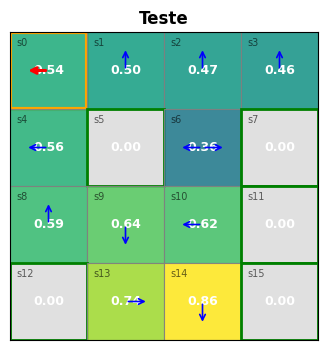

In [31]:
vis.desenhar(V, pi, titulo="Teste")
plt.show()

#Explicação: por que as setas do Lago Congelado escorregadio parecem "estranhas"
O resultado acima não é um bug de conversão de ações nem de desenho. Ele é a política ótima do MDP escorregadio (is_slippery=True).

No modo escorregadio, a ação escolhida só acontece com probabilidade 1/3. Nas outras duas ocasiões o agente desliza para um dos dois lados perpendiculares (ex.: Baixo pode resultar em Esquerda, Baixo ou Direita). Por isso a política ótima não aponta para o próximo estado desejado. Ela escolhe, em cada estado, a ação que evita buracos entre os resultados possíveis sempre que isso é possível, usando o escorregão a favor do agente.

As células a seguir:

resolvem o problema nos dois modos (escorregadio e determinístico) e comparam os desenhos;
verificam a conversão de ações contra uma Value Iteration feita direto sobre o P do Gym, sem conversão;
mostram, para cada estado do caminho esperado, os resultados possíveis da ação escolhida.
Também trocamos o rastro vermelho. _simular_politica segue a transição de maior probabilidade e, no modo escorregadio, as três têm 1/3, então o rastro ficava só em s0. O novo visualizador destaca os estados com número esperado de passos relevante (contando as permanências no mesmo estado), calculado a partir de s0.

In [32]:
# Auxiliares: Tabuleiro sem ruído (sem prints/figuras a cada reset) e visualizador com rastro esperado
class TabuleiroSilencioso(Tabuleiro):
    """Mesmo Tabuleiro, sem os prints de teste e sem desenhar a cada reset/step."""
    def _test__state_to_coords(self): pass
    def _test_coords_to_state(self): pass
    def render(self): pass

In [33]:
class VisualizadorEsperado(VisualizadorResultado):
    """Rastro = estados com número esperado de visitas >= limiar, partindo de s0.
    Em MDP estocástico isso substitui o 'caminho mais provável', que é ambíguo
    quando as transições empatam (como no FrozenLake escorregadio)."""

    def __init__(self, tab, cmap_valores="viridis", limiar=0.05):
        super().__init__(tab, cmap_valores)
        self.limiar = limiar

    def visitas_esperadas(self, politica, s0=None):
        tab = self.tab
        S = tab.num_estados
        s0 = tab.estado_inicial if s0 is None else s0
        Pm = np.zeros((S, S))
        for s in range(S):
            if tab._is_terminal(s):
                continue
            acoes = politica[s] if isinstance(politica[s], list) else [politica[s]]
            for a in acoes:
                for p, s2, r, d in tab.P_Din_MDP[s][int(a)]:
                    Pm[s, s2] += p / len(acoes)
        trans = [s for s in range(S) if not tab._is_terminal(s)]
        Q = Pm[np.ix_(trans, trans)]
        N = np.linalg.inv(np.eye(len(trans)) - Q)   # matriz fundamental da cadeia absorvente
        visitas = np.zeros(S)
        visitas[trans] = N[trans.index(s0)]
        return visitas

    def _simular_politica(self, politica, s0=None, max_passos=500):
        try:
            v = self.visitas_esperadas(politica, s0)
        except np.linalg.LinAlgError:       # sem estado absorvente alcançável: usa o método original
            return super()._simular_politica(politica, s0, max_passos)
        return [int(s) for s in np.argsort(-v) if v[s] >= self.limiar]

In [34]:
def resolver(slippery, gamma=0.99):
    env_gym = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=slippery)
    P_gym = env_gym.unwrapped.P
    tab = TabuleiroSilencioso(build_my_P(P_gym), nlin=4, ncol=4)
    aval = AvaliadorVetorizado(tab, xp=cp if GPU_DISPONIVEL else np, gamma=gamma)
    V, pi = IteracaoValor(tab, aval).treinar()
    return dict(P_gym=P_gym, tab=tab, V=V, pi=pi)


[IteracaoValor | AvaliadorVetorizado] convergiu em 306 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 7 iterações.


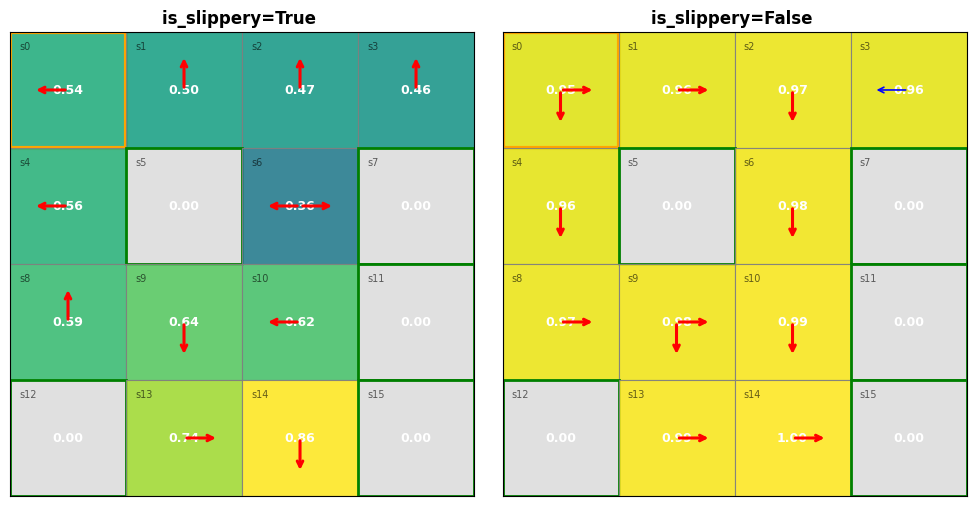

In [35]:
# Escorregadio x determinístico, lado a lado
resultados = {True: resolver(True), False: resolver(False)}
titulos = {True: "is_slippery=True ", False: "is_slippery=False "}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (slippery, r) in zip(axes, resultados.items()):
    VisualizadorEsperado(r["tab"]).desenhar(r["V"], r["pi"], ax=ax, titulo=titulos[slippery])
plt.tight_layout()
plt.show()